In [1]:
import numpy as np
from pyscf import gto, fci

In [2]:
r_list = np.concatenate((np.linspace(0.4, 3.0, 53), np.linspace(3.2, 6.0, 15)))
bas = '6-31g'

In [3]:
hf_list = []
fci_list = []
for r in r_list:
    mol = gto.M(atom=f'H; H 1 {r}', basis=bas, charge=0, spin=0)
    mf = mol.RHF()
    mf.kernel()
    hf_list.append(mf.e_tot)
    myci = fci.FCI(mf)
    myci.kernel()
    fci_list.append(myci.e_tot)
    print(f'r = {r:.2f}, HF energy = {mf.e_tot:.6f}, FCI energy = {myci.e_tot:.6f}')

converged SCF energy = -0.93300420061077
r = 0.40, HF energy = -0.933004, FCI energy = -0.950679
converged SCF energy = -1.00833520950261
r = 0.45, HF energy = -1.008335, FCI energy = -1.027107
converged SCF energy = -1.05802481296927
r = 0.50, HF energy = -1.058025, FCI energy = -1.077864
converged SCF energy = -1.09016083520405
r = 0.55, HF energy = -1.090161, FCI energy = -1.111046
converged SCF energy = -1.11003089523311
r = 0.60, HF energy = -1.110031, FCI energy = -1.131953
converged SCF energy = -1.12119781786402
r = 0.65, HF energy = -1.121198, FCI energy = -1.144164
converged SCF energy = -1.12612316138391
r = 0.70, HF energy = -1.126123, FCI energy = -1.150157
converged SCF energy = -1.12654503453569
r = 0.75, HF energy = -1.126545, FCI energy = -1.151689
converged SCF energy = -1.12371293600753
r = 0.80, HF energy = -1.123713, FCI energy = -1.150028
converged SCF energy = -1.11853710195565
r = 0.85, HF energy = -1.118537, FCI energy = -1.146104
converged SCF energy = -1.1116

In [4]:
np.save('HF', np.array(hf_list))
np.save('FCI', np.array(fci_list))

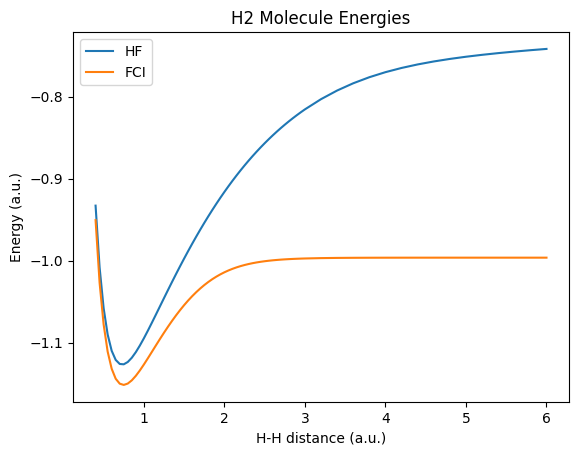

In [5]:
import matplotlib.pyplot as plt

plt.plot(r_list, hf_list, label='HF')
plt.plot(r_list, fci_list, label='FCI')
plt.xlabel('H-H distance (a.u.)')
plt.ylabel('Energy (a.u.)')
plt.title('H2 Molecule Energies')
plt.legend()
plt.show()